# Counterfactual Sampling on the DecFM 2D Mixture: RBF-Kernel MMD Flow (Forward Euler)

Doubly robust counterfactual sampling on a two-dimensional confounded design. The counterfactual
outcome distribution is represented by its cross-fitted doubly robust mean embedding, and samples
are generated by transporting particles toward this embedding with the forward-Euler MMD gradient
flow under a Gaussian (RBF) kernel.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float64)

from kernel_utils import RBF
from data_utils import sample_decfm_2d_data
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import LogisticPropensityModel, crossfit_propensity
from mmd_flow_utils import mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

np.random.seed(42)
torch.manual_seed(42)

## 1. Data Generation

Two-dimensional mixture-of-normals design of Dance et al. (2026, Appendix B.2.2):

$$
X \sim \mathcal N(0, I_2), \qquad
A \mid x \sim \mathrm{Bernoulli}\big(\sigma(\gamma\, w^\top x)\big), \quad w = (1, -1)/\sqrt 2,
$$

$$
Y = X + \varepsilon, \qquad
\varepsilon \sim \tfrac12 \mathcal N(0, \sigma^2 I_2) + \tfrac12 \mathcal N\big((\delta, \delta), \sigma^2 I_2\big),
$$

with $\gamma = 3$, $\delta = 2$, $\sigma = 0.2$. The outcome does not depend on $A$, so both
interventional laws $P_{Y(a)}$ equal the marginal $P_Y$, while the observed arms
$P_{Y \mid A = a} \neq P_Y$ under confounding. The task is to deconfound each observed arm back to
the marginal.

In [2]:
n, m = 4000, 1000
data = sample_decfm_2d_data(n_samples=n, confounding_strength=3.0, mixture_delta=2.0, seed=601)
X, A_logged, Y_logged = data["X"], data["A_logged"], data["Y_logged"]
Y_oracle = data["Y_oracle"]
A_flat = A_logged.ravel()

## 2. CPME Weight Fitting

The counterfactual mean embedding under the deterministic intervention $A = a$ is estimated as a
finite expansion over the logged outcomes, $\hat\chi(a) = \sum_i v_i\, k_Y(y_i, \cdot)$, with the
one-step doubly robust weights of Zenati et al. (2025),

$$
v_{\mathrm{DR}} = \underbrace{\tfrac1n (K + \lambda I)^{-1} (K_X \circ K_A^{a}) \mathbf 1}_{\text{plug-in}}
\; + \; \tfrac1n \big[\hat w - (K + \lambda I)^{-1} K \hat w\big],
\qquad K = K_X \circ K_A,
$$

where $\hat w_i = \mathbf 1\{a_i = a\} / \hat e_a(x_i)$ and $\hat e_a$ is a plug-in logistic
propensity (`dens_ratio_utils.LogisticPropensityModel`). All nuisances are **cross-fitted** on one shared 5-fold split: the propensity, the
conditional mean embedding behind both terms, and the ridge parameter $\lambda$ (selected by
cross-validation within each training block) are fit out-of-fold, so no observation is used to
train its own nuisance predictions.

In [3]:
fold_ids = make_crossfit_fold_ids(n, n_folds=5, seed=0)
propensity = crossfit_propensity(X, A_flat, fold_ids,
                                 model_factory=LogisticPropensityModel)

kernel_x = RBF(use_length_scale_heuristic=True)
kernel_a = RBF(length_scale=0.5)
kernel_y = RBF(use_length_scale_heuristic=True)
K_x, K_a = kernel_x(X), kernel_a(A_logged)
_ = kernel_y(Y_logged)

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Y_logged[train, 0], seed=0)

v_dr = {}
for a in (0, 1):
    e_a = propensity if a == 1 else 1.0 - propensity
    w_hat = (A_flat == a).double() / e_a
    K_a_target = kernel_a(A_logged, torch.full((n, 1), float(a)))
    v_dr[a] = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids, fold_lambdas)
    print(f"arm {a}:  sum(v) = {v_dr[a].sum():.3f}   sum|v| = {v_dr[a].abs().sum():.3f}")

arm 0:  sum(v) = 0.983   sum|v| = 1.000


arm 1:  sum(v) = 1.002   sum|v| = 1.031


## 3. MMD Flow

Particles are initialised at the observed outcomes of the corresponding arm and transported by the
MMD gradient flow (Arbel et al., 2019) toward the estimated embedding, minimising

$$
\mathcal F(Q) = \tfrac12\, \big\lVert \mu_Q - \hat\chi(a) \big\rVert_{\mathcal H_Y}^2 ,
\qquad
y_j^{(r+1)} = y_j^{(r)} - \gamma\, \nabla f\big(y_j^{(r)}\big),
$$

where $f = \mu_{Q_r} - \hat\chi(a)$ is the witness function. The step size scales with the squared
kernel bandwidth.

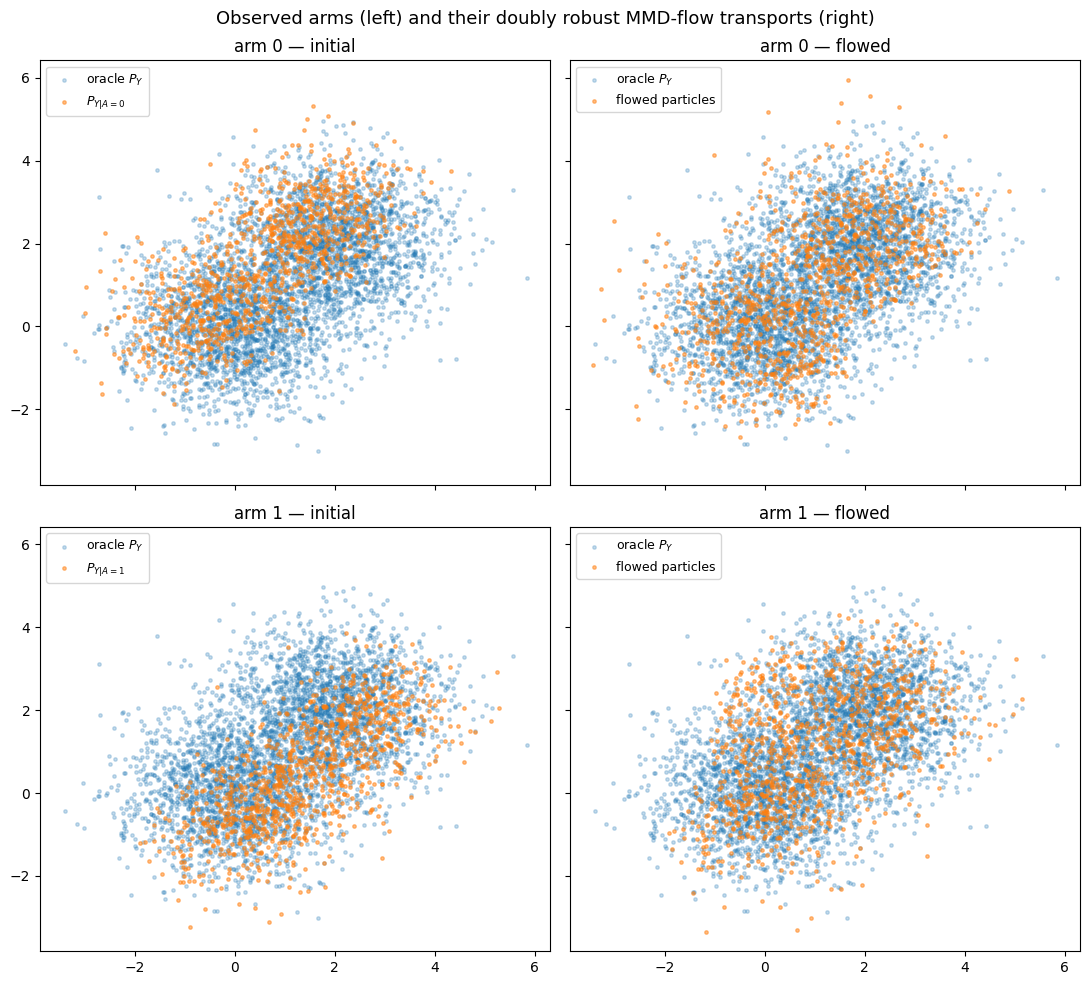

In [4]:
step_size = 0.05 * kernel_y.length_scale.item() ** 2
particles = {}
for a in (0, 1):
    arm_idx = torch.nonzero(A_flat == a).ravel()
    generator = torch.Generator().manual_seed(0)
    init = Y_logged[arm_idx[torch.randperm(len(arm_idx), generator=generator)[:m]]].clone()
    flowed, _ = mmd_gradient_flow(kernel_y, Y_logged, init, step_size=step_size,
                                  n_iterations=3000, target_weights=v_dr[a], verbose=False)
    particles[a] = {"initial": init, "flowed": flowed}

fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
for a in (0, 1):
    for column, stage in enumerate(("initial", "flowed")):
        ax = axes[a, column]
        ax.scatter(*np.asarray(Y_oracle).T, s=6, alpha=0.25, label="oracle $P_Y$")
        ax.scatter(*np.asarray(particles[a][stage]).T, s=6, alpha=0.5,
                   label=f"$P_{{Y|A={a}}}$" if stage == "initial" else "flowed particles")
        ax.set_title(f"arm {a} — {stage}")
        ax.legend(fontsize=9, loc="upper left")
fig.suptitle("Observed arms (left) and their doubly robust MMD-flow transports (right)", fontsize=13)
fig.tight_layout()
plt.show()

## 4. Metric Evaluation

Sliced Wasserstein distances of orders 1 and 2 and unbiased squared MMD between each sample and a
fresh oracle draw of $P_Y$; the distances between two disjoint oracle subsamples of the same size
give the finite-sample floors. All estimators follow the evaluation code of Dance et al. (2026) —
verified to numerical identity — so the reported values are directly comparable with that paper,
which uses Wasserstein-1 for its low-dimensional synthetic and benchmark tables and Sliced
Wasserstein-2 for its image experiments.

The sample size $n = 4000$ keeps both arms' effective sample sizes comfortably large; at small $n$
the on-arm effective sample size can collapse for unlucky draws and the importance-weighted target
degrades sharply (see the overlap analysis in `NotebookExamples/dgp_analysis`).

In [5]:
def evaluate(cloud):
    sw1 = sliced_wasserstein(cloud, Y_oracle, p=1, seed=0).item()
    sw2 = sliced_wasserstein(cloud, Y_oracle, p=2, seed=0).item()
    mmd2 = squared_mmd(kernel_y, cloud, Y_oracle, unbiased=True).item()
    return sw1, sw2, mmd2


print(f"{'sample':28s} {'SW1':>8s} {'SW2':>8s} {'MMD^2 (unbiased)':>18s}")
for a in (0, 1):
    rows = {f"observed arm {a}": Y_logged[A_flat == a],
            f"flowed arm {a}": particles[a]["flowed"]}
    for name, cloud in rows.items():
        sw1, sw2, mmd2 = evaluate(cloud)
        print(f"{name:28s} {sw1:8.3f} {sw2:8.3f} {mmd2:18.2e}")

floor_x, floor_y = Y_oracle[:m], Y_oracle[m:2 * m]
sw1_floor = sliced_wasserstein(floor_x, floor_y, p=1, seed=0).item()
sw2_floor = sliced_wasserstein(floor_x, floor_y, p=2, seed=0).item()
mmd2_floor = squared_mmd(kernel_y, floor_x, floor_y, unbiased=True).item()
print(f"{'oracle-vs-oracle floor':28s} {sw1_floor:8.3f} {sw2_floor:8.3f} {mmd2_floor:18.2e}")

sample                            SW1      SW2   MMD^2 (unbiased)


observed arm 0                  0.421    0.488           4.05e-02


flowed arm 0                    0.111    0.150           7.38e-04


observed arm 1                  0.437    0.512           4.97e-02


flowed arm 1                    0.109    0.159           2.28e-03


oracle-vs-oracle floor          0.061    0.086          -4.20e-04
